In [1]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import logging
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, r2_score

from sklearn import set_config

pd.set_option('display.max_columns',50) # setting up the dataframe display columns
pd.set_option('display.max_colwidth', 100) # setting up column width 100

set_config(display = 'text') 

#### Loading the US Retail Sales data

In [2]:
file_dataset= 'us_retail_sales.csv' # file is saved in current directory.

# Catch any exception reading file
try:
    df_sales = pd.read_csv(f"{file_dataset}")
except FileNotFoundError as e: # if file is not not found. 
    logging.error(f"{file_dataset} is not found, please check the file path or name.\n{e}")

In [3]:
df_sales.head()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
0,1992,146925,147223,146805,148032,149010,149800,150761.0,151067.0,152588.0,153521.0,153583.0,155614.0
1,1993,157555,156266,154752,158979,160605,160127,162816.0,162506.0,163258.0,164685.0,166594.0,168161.0
2,1994,167518,169649,172766,173106,172329,174241,174781.0,177295.0,178787.0,180561.0,180703.0,181524.0
3,1995,182413,179488,181013,181686,183536,186081,185431.0,186806.0,187366.0,186565.0,189055.0,190774.0
4,1996,189135,192266,194029,194744,196205,196136,196187.0,196218.0,198859.0,200509.0,200174.0,201284.0


Dataframe is in Wide Format where months are the columns. For Time-series models, I need to convert this format into Long Format where every row is a single point in time and a sales value.

In [4]:
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   YEAR    30 non-null     int64  
 1   JAN     30 non-null     int64  
 2   FEB     30 non-null     int64  
 3   MAR     30 non-null     int64  
 4   APR     30 non-null     int64  
 5   MAY     30 non-null     int64  
 6   JUN     30 non-null     int64  
 7   JUL     29 non-null     float64
 8   AUG     29 non-null     float64
 9   SEP     29 non-null     float64
 10  OCT     29 non-null     float64
 11  NOV     29 non-null     float64
 12  DEC     29 non-null     float64
dtypes: float64(6), int64(7)
memory usage: 3.2 KB


In [5]:
# Using pd.melt to convert dataframe in long format
df_long = pd.melt(df_sales, id_vars = "YEAR", 
                  var_name="MONTH", value_name="Sales")
df_long.head()

,YEAR,MONTH,Sales
0,1992,JAN,146925.0
1,1993,JAN,157555.0
2,1994,JAN,167518.0
3,1995,JAN,182413.0
4,1996,JAN,189135.0


I am combining Year and Month columns to create a new column "Date".

In [6]:
# pandas.to_datetime
df_long['Date'] = pd.to_datetime(
                df_long['YEAR'].astype(str) + '-' + df_long['MONTH'], 
                format='%Y-%b')

df_long.head()

,YEAR,MONTH,Sales,Date
0,1992,JAN,146925.0,1992-01-01
1,1993,JAN,157555.0,1993-01-01
2,1994,JAN,167518.0,1994-01-01
3,1995,JAN,182413.0,1995-01-01
4,1996,JAN,189135.0,1996-01-01


Sorting the dataframe by Date, resetting the index and dropping NaN values.

In [7]:
df = df_long.copy()
df = df_long.sort_values('Date').dropna().reset_index()
df.head()

,index,YEAR,MONTH,Sales,Date
0,0,1992,JAN,146925.0,1992-01-01
1,30,1992,FEB,147223.0,1992-02-01
2,60,1992,MAR,146805.0,1992-03-01
3,90,1992,APR,148032.0,1992-04-01
4,120,1992,MAY,149010.0,1992-05-01


Dropping index, YEAR and MONTH columns

In [8]:
df = df[["Date", "Sales"]]
df.head()

,Date,Sales
0,1992-01-01,146925.0
1,1992-02-01,147223.0
2,1992-03-01,146805.0
3,1992-04-01,148032.0
4,1992-05-01,149010.0


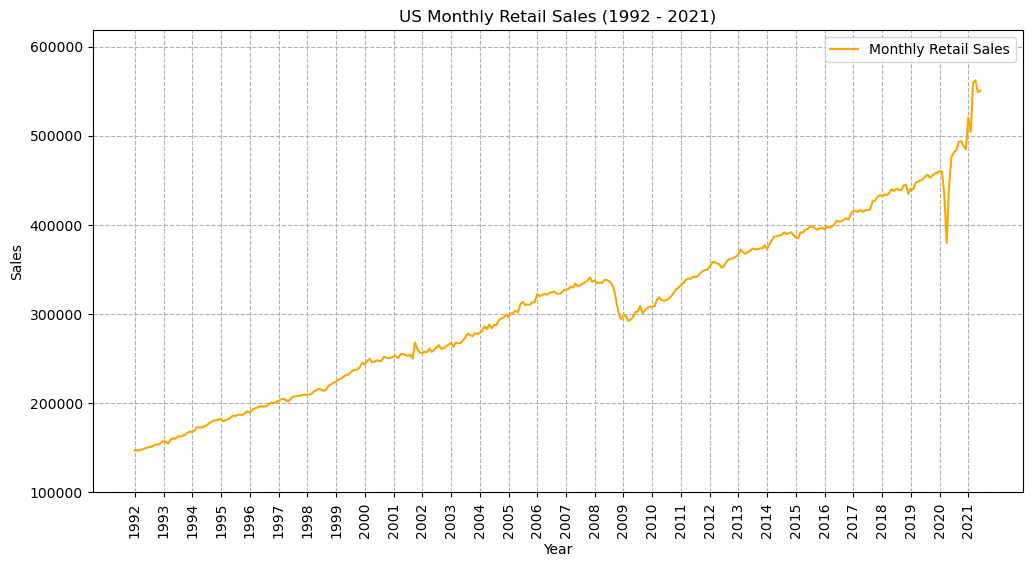

In [9]:
# Line graph
plt.figure(figsize=(12, 6))
plt.plot( df['Date'] ,  df['Sales'], label='Monthly Retail Sales', 
          color='orange')

# showing each year on x axis
years = range(1992, 2022)
plt.xticks([f"{y}-01-01" for y in years], years, rotation=90)

plt.ylim(100000, df['Sales'].max() * 1.1)

plt.title('US Monthly Retail Sales (1992 - 2021)')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.grid(True, linestyle='--')
plt.legend()
plt.show()

The graph provides almost 30 years of US retail history. A consistent upward trend shows a growing economy over 30 years. When I look at the data, there is always some increase in sales at the end of the year. It shows that holiday shopping in November and December increases sales.

There is also a sharp dip in sales during 2008 to 2000. In 2008, there was a massive financial crisis followed by a recession. It took 3 years to get sales back to where they were before the crash.

In early 2020, during COVID-19 and the initial lockdowns, I saw a sharp drop in sales. When the situation improved and vaccines became available, sales shot up faster in 2021. 

In general, trends show an upward slope from left to right, and US retail sales are expanding except during a 2008 financial and 2020 health crisis,

####  Spliting the data into Train and Test.

Time Series Modeling requires data in a chronological sequence, so I avoid shuffling to preserve the time-based relationships.


In [10]:
# Training data- unitl June 2020
train = df[df['Date'] < '2020-07-01']

# Test data-  July 2020 – June 2021
test = df[df['Date'] >= '2020-07-01']

#### Model building and testing

SARIMA (Seasonal AutoRegressive Integrated Moving Average) model not only looks at the immediate neighbors (like predicting Feb based on Jan), but also has a  seasonal component that checks the same month in previous years (predicting Dec 2020 based on Dec 2019).

In SARIMA model, it needs  two sets of parameters: (p, d, q) for the general trend and (P, D, Q, s) for the seasonal pattern, and for retail data s is always 12.

In [11]:
# starting points- p,d,q = 1,1,1 and P,D,Q,s = 1,1,1,12
model_s = SARIMAX(train['Sales'], order=(1, 1, 1), 
                  seasonal_order=(1, 1, 1, 12) )

In [12]:
# model fitting and training
sarima_result = model_s.fit()

In [13]:
# model prediction

# 'steps' is the number of months in test data, I have 12.
forecast_results = sarima_result.get_forecast(steps=len(test))

Model picks the last known date that is  June 2020 and forcast the sales values in the future.

In [14]:
# predicted sales values
y_pred = forecast_results.predicted_mean

In [15]:
# Comparing actual test sales with predictions, and calcualting the mean squared error
mse = mean_squared_error(test['Sales'], y_pred)

# root mean squared error 
rmse = np.sqrt(mse)

print(f"Mean Squared Error (MSE): {mse:,.2f}","\n")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")


Mean Squared Error (MSE): 3,517,353,714.36 

Root Mean Squared Error (RMSE): 59,307.28


On average, monthly sales prediction by model is off by 59,307.28. 

It looks like the model score is affected by extreme historical events, such as the 2008 Financial Crisis and the 2020 COVID pandemic.